# PEDS Section B · rater agreement

Reads the team Google Sheet and measures how well ratings agree, item by item, for three comparisons:

| Comparison | What is paired |
|---|---|
| **Street View: rater vs rater** | Two raters' Street View ratings of the same segment |
| **Field: rater vs rater** | Two raters' field ratings of the same segment (same walk or a later visit) |
| **Field vs Street View** | Each field rating against each Street View rating of the same segment |

For each PEDS item it reports % agreement with the count behind it (e.g. 49 / 51), and for the ordered items, agreement within one category. The results are descriptive: they show how this team's ratings of these segments lined up, with no confidence intervals. Chance-corrected statistics (Cohen's kappa, weighted kappa, Gwet's AC1) are in an appendix table for comparison with published PEDS reliability studies.

**To run:** set `AREA` in the next cell, then *Run All*. The sheet has to stay shared as "Anyone with the link can view". Without internet, download each tab as CSV and set `CSV_DIR`.

Data still coming in is fine. Segments without a pair are listed in section 3 and left out of the statistics until both ratings exist.

In [37]:
import os, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Compat: pandas 2.x Styler uses matplotlib.colormaps (added in mpl 3.5); this env has mpl 3.4
import matplotlib as mpl
if not hasattr(mpl, "colormaps"):
    import matplotlib.cm as _cm
    class _CmapRegistry:
        def __getitem__(self, name): return _cm.get_cmap(name)
        def get_cmap(self, name=None): return _cm.get_cmap(name)
    mpl.colormaps = _CmapRegistry()
from IPython.display import display, Markdown

pd.set_option("display.max_rows", 300)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
warnings.filterwarnings("ignore", category=RuntimeWarning)

## 1 · Settings

In [38]:
AREA = os.environ.get("PEDS_AREA", "Rockridge")      # "Rockridge" or "Chinatown"

SHEET_ID = "138fddMR4QTbVl-1OLKtzmpRe9e7AmBrOimVOB0XFACw"
TABS = {   # tab ids (the gid=... number in the sheet's address bar when that tab is open)
    "Rockridge": {"gsv": ["1106687304"],                 # "GSV entries"
                  "field": ["1073847775"]},              # "Rockridge Field entries"
    "Chinatown": {"gsv": ["1174797972"],                 # "Chinatown GSV entries"
                  "field": ["1352016008", "91276802"]},  # "Chinatown Field 1", "Chinatown Field 2"
}
# Visit number for each field tab. This overrides the sheet's own visit column, which reads 1
# on every row of "Chinatown Field 2".
VISIT_FOR_TAB = {"1352016008": 1, "91276802": 2}

# Offline: a folder holding each tab as <gid>.csv. Leave as None to read the live sheet.
CSV_DIR = os.environ.get("PEDS_CSV_DIR") or None

# Which field ratings count as a pair: "any" (default), "same_visit" (raters who walked together)
# or "across_visits" (visit 1 vs visit 2, as in Chinatown).
FIELD_PAIRING = "any"
# Count one rater's visit-1 and visit-2 ratings of a segment as a field pair (e.g. Chinatown FRK St,
# walked by one rater on both visits). Set False to keep field pairs strictly between different raters.
SAME_RATER_ACROSS_VISITS = True

# Names are matched on the first word ("Michael Huang" = "Michael"). Add exceptions here.
RATER_ALIASES = {}   # e.g. {"Mike": "Michael"}

EXPORT_XLSX = f"{AREA}_rater_agreement.xlsx"

## 2 · Codebook and area rules

The 27 PEDS items plus Q13. Check-all questions are stored as one 0/1 column per box.

The Chinatown rules are the alignment agreed earlier, giving 163 segments:
- Route E is dropped, along with the six blocks that have no sidewalk and Alice St 10th–11th.
- Seven pairs of half-blocks are joined. A rater who rated both halves is merged worst-case.
- Three visit-2 placeholder rows are ignored.

Rockridge needs no alignment: the 52 north box segments are used as they are.

In [39]:
ITEMS = ["no_sidewalk",
         "q4_footpath", "q4_paved_trail", "q4_sidewalk", "q4_ped_street",
         "q5_asphalt", "q5_concrete", "q5_brick_stone", "q5_gravel", "q5_dirt_sand",
         "q6_condition",
         "q7_poles_signs", "q7_parked_cars", "q7_greenery", "q7_garbage_cans", "q7_other", "q7_none",
         "q8_fence", "q8_trees", "q8_hedges", "q8_landscape", "q8_grass", "q8_none",
         "q9_dist_from_curb", "q10_width", "q11_curb_cuts", "q12_complete"]
Q13 = "q13_connections"
ALL = ITEMS + [Q13]
GROUPS = {"q4": ITEMS[1:5], "q5": ITEMS[5:10], "q7": ITEMS[11:17], "q8": ITEMS[17:23]}
GROUP_NAME = {"q4": "Q4 Sidewalk type", "q5": "Q5 Path material", "q7": "Q7 Obstructions", "q8": "Q8 Buffers"}
BINARY = ["no_sidewalk"] + sum(GROUPS.values(), [])
CODES = {"q6_condition": [1, 2, 3, 4], "q9_dist_from_curb": [1, 2, 3], "q10_width": [1, 2, 3],
         "q11_curb_cuts": [1, 2, 3], "q12_complete": [1, 2]}
ORDINAL = ["q6_condition", "q9_dist_from_curb", "q10_width", "q11_curb_cuts", Q13]
LABEL = {"no_sidewalk": "No sidewalk", "q4_footpath": "Q4 Footpath", "q4_paved_trail": "Q4 Paved trail",
         "q4_sidewalk": "Q4 Sidewalk", "q4_ped_street": "Q4 Pedestrian street", "q5_asphalt": "Q5 Asphalt",
         "q5_concrete": "Q5 Concrete", "q5_brick_stone": "Q5 Brick/stone", "q5_gravel": "Q5 Gravel",
         "q5_dirt_sand": "Q5 Dirt/sand", "q6_condition": "Q6 Condition", "q7_poles_signs": "Q7 Poles/signs",
         "q7_parked_cars": "Q7 Parked cars", "q7_greenery": "Q7 Greenery", "q7_garbage_cans": "Q7 Garbage cans",
         "q7_other": "Q7 Other", "q7_none": "Q7 None", "q8_fence": "Q8 Fence", "q8_trees": "Q8 Trees",
         "q8_hedges": "Q8 Hedges", "q8_landscape": "Q8 Landscape", "q8_grass": "Q8 Grass", "q8_none": "Q8 None",
         "q9_dist_from_curb": "Q9 Distance from curb", "q10_width": "Q10 Width", "q11_curb_cuts": "Q11 Curb cuts",
         "q12_complete": "Q12 Complete", Q13: "Q13 Connections"}

RULES = {
    "Rockridge": dict(drop=set(), drop_prefix=(), alias={}, combine={}, placeholders=set()),
    "Chinatown": dict(
        # route E (6th St north side, Fallon St west side), blocks with no sidewalk, Lincoln Square Park
        drop={"10TH BWY–FRK N", "10TH BWY–FRK S", "10TH FRK–WEB N", "10TH FRK–WEB S",
              "11TH OAK–FAL N", "11TH OAK–FAL S", "ALI 10–11 W", "ALI 10–11 E"},
        drop_prefix=("6TH ", "FAL "),
        alias={"BWY 9–11 E": "BWY 09–11 E", "FRK 9–11 W": "FRK 09–11 W", "FRK 9–11 E": "FRK 09–11 E"},
        combine={"BWY 09–11 E": ["BWY 09–10 E", "BWY 10–11 E"], "FRK 09–11 W": ["FRK 09–10 W", "FRK 10–11 W"],
                 "FRK 09–11 E": ["FRK 09–10 E", "FRK 10–11 E"], "WEB 09–11 W": ["WEB 09–10 W", "WEB 10–11 W"],
                 "OAK 10–12 E": ["OAK 10–11 E", "OAK 11–12 E"],
                 "10TH HAR–JAC N": ["10TH HAR–ALI N", "10TH ALI–JAC N"],
                 "11TH HAR–JAC S": ["11TH HAR–ALI S", "11TH ALI–JAC S"]},
        # visit-2 rows marked "no sidewalk" with a "combine" note; the other half holds the rating
        placeholders={"BWY 10–11 E", "FRK 10–11 E", "FRK 09–10 W"}),
}
R = RULES[AREA]
HALF = {h: f for f, hs in R["combine"].items() for h in hs}
def final_code(code):
    c = R["alias"].get(code, code)
    return HALF.get(c, c)
def dropped(code):
    return code in R["drop"] or code.startswith(R["drop_prefix"])

## 3 · Load and clean

In [40]:
def read_tab(gid):
    src = os.path.join(CSV_DIR, f"{gid}.csv") if CSV_DIR else \
          f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=csv&gid={gid}"
    raw = pd.read_csv(src, header=None, dtype=str, keep_default_na=False)
    # the header is the first row naming seg_code/seg_num (Chinatown Field 1 has a label row above it)
    hdr = next(i for i in range(min(5, len(raw))) if {"seg_code", "seg_num"} & set(raw.iloc[i].str.strip()))
    cols = [c.strip() for c in raw.iloc[hdr]]
    if "seg_code" not in cols and cols.count("seg_num") > 1:      # Chinatown GSV: code column headed seg_num
        cols[[i for i, c in enumerate(cols) if c == "seg_num"][1]] = "seg_code"
    df = raw.iloc[hdr + 1:].copy()
    df.columns = cols
    df = df.loc[:, [c != "" for c in df.columns]]
    df = df.loc[:, ~df.columns.duplicated()]
    df["tab"] = gid
    return df.reset_index(drop=True)

problems = []   # data-entry issues found while cleaning
def note(df_row, method, item, issue):
    problems.append(dict(method=method, seg_code=df_row["seg_code"], rater=df_row["rater"], item=item, issue=issue))

def allowed(item, method):
    if item in BINARY: return {0, 1}
    if item in CODES: return set(CODES[item]) | ({9} if method == "gsv" else set())
    return None   # Q13: any whole number

def clean(df, method):
    df = df.copy()
    for c in df.columns:
        df[c] = df[c].astype(str).str.strip()
    df = df[df["seg_code"] != ""]
    test = df["rater"].str.endswith("(TEST)") | (df["rater"] == "__setup_test__") | (df["seg_code"] == "SETUP-CHECK")
    df = df[~test & (df["rater"] != "")].copy()
    first = df["rater"].str.split().str[0].str.title()
    df["rater_id"] = first.map(lambda r: RATER_ALIASES.get(r, r))
    if method == "field":
        v = pd.to_numeric(df["visit"], errors="coerce") if "visit" in df else pd.Series(np.nan, index=df.index)
        df["visit"] = df["tab"].map(VISIT_FOR_TAB).fillna(v).fillna(1).astype(int)
    else:
        df["visit"] = 0
    for c in ALL:
        if c not in df: df[c] = ""
    out = pd.DataFrame(index=df.index)
    for it in ALL:
        s = df[it]
        num = pd.to_numeric(s, errors="coerce")
        ok = allowed(it, method)
        bad = (s != "") & (num.isna() | (num % 1 != 0) | (num < 0) | (num.isin(ok) == False if ok else False))
        for i in df.index[bad]:
            note(df.loc[i], method, it, f"value {s[i]!r} is not a valid code; treated as missing")
        out[it] = num.where(~bad)
    if method == "field":
        # Chinatown Field 1 left unchecked boxes blank: a blank box counts as 0 when its question was answered
        answered = out[ALL].notna().any(axis=1)
        out.loc[answered & out["no_sidewalk"].isna(), "no_sidewalk"] = 0
        for g, its in GROUPS.items():
            any_yes = (out[its] == 1).any(axis=1) & (out["no_sidewalk"] == 0)
            out.loc[any_yes, its] = out.loc[any_yes, its].fillna(0)
    else:
        for g, its in GROUPS.items():                                   # "can't tell" box: the question is missing
            ct = pd.to_numeric(df.get(f"{g}_cant_tell", ""), errors="coerce") == 1
            out.loc[ct, its] = np.nan
        for it in CODES: out.loc[out[it] == 9, it] = np.nan              # 9 = can't tell
        out.loc[out[Q13] == 99, Q13] = np.nan                            # 99 = can't tell
    # contradictions worth a look: "none" checked together with another box
    for g in ("q7", "q8"):
        its = GROUPS[g]; none = its[-1]
        clash = (out[none] == 1) & (out[its[:-1]] == 1).any(axis=1)
        for i in df.index[clash]:
            note(df.loc[i], method, none, "'None' checked together with another box")
    meta = df[["seg_code", "rater", "rater_id", "visit", "tab"] +
              [c for c in ("view_quality", "received_at", "saved_at", "note") if c in df]]
    res = pd.concat([meta, out], axis=1)
    res["method"] = method
    res["blank"] = out[ALL].isna().all(axis=1)
    return res

raw = {m: pd.concat([read_tab(g) for g in TABS[AREA][m]], ignore_index=True) for m in ("gsv", "field")}
data = pd.concat([clean(raw["gsv"], "gsv"), clean(raw["field"], "field")], ignore_index=True)
print({m: len(raw[m]) for m in raw}, "rows read;", len(data), "rated rows after removing test rows")

{'gsv': 103, 'field': 104} rows read; 207 rated rows after removing test rows


In [41]:
# Keep one rating per segment, rater, visit and method (the latest one sent, when a rating was resent)
log = []
data["order"] = pd.to_datetime(data.get("received_at"), errors="coerce", utc=True)
data = data.sort_values("order", kind="stable", na_position="first")
dup = data.duplicated(["method", "seg_code", "rater_id", "visit"], keep="last")
for _, r in data[dup].iterrows():
    log.append(dict(method=r.method, seg_code=r.seg_code, rater=r.rater_id, action="duplicate row; the latest copy was kept"))
data = data[~dup]

# Area rules: drop segments that are not in the study, ignore blanks / not viewable / placeholders
keep = []
for _, r in data.iterrows():
    why = None
    if dropped(r.seg_code): why = "segment not in the study area"
    elif r.method == "gsv" and str(r.get("view_quality", "")).strip() == "3": why = "marked not viewable in Street View"
    elif r.blank: why = "blank row (no answers)"
    elif r.seg_code in R["placeholders"] and r.no_sidewalk == 1: why = "placeholder for a combined block; the other half was used"
    if why: log.append(dict(method=r.method, seg_code=r.seg_code, rater=r.rater_id, action=why))
    keep.append(why is None)
data = data[keep].copy()
data["segment"] = data["seg_code"].map(final_code)

def worst(rows):
    # Merge halves of one block face rated separately: the poorer answer wins
    m = {}
    for it in ALL:
        v = rows[it].dropna()
        if v.empty: m[it] = np.nan
        elif it.endswith("_none"): m[it] = v.min()                         # 'none' only if both halves had none
        elif it == "q6_condition": m[it] = v[v != 4].min() if (v != 4).any() else 4
        elif it in ("q9_dist_from_curb", "q10_width"): m[it] = v.min()
        else: m[it] = v.max()           # a box ticked on either half, more curb cuts, incomplete, more connections
    return pd.Series(m)

parts = []
for key, g in data.groupby(["method", "segment", "rater_id", "visit"], sort=False):
    if len(g) > 1:
        log.append(dict(method=key[0], seg_code=key[1], rater=key[2],
                        action="halves " + " + ".join(g.seg_code) + " merged (worst case)"))
        row = worst(g)
    else:
        row = g.iloc[0][ALL]
    parts.append(pd.concat([pd.Series(dict(zip(["method", "segment", "rater_id", "visit"], key))), row]))
ratings = pd.DataFrame(parts).reset_index(drop=True)
for c in ALL: ratings[c] = pd.to_numeric(ratings[c])
log = pd.DataFrame(log, columns=["method", "seg_code", "rater", "action"])
problems = pd.DataFrame(problems, columns=["method", "seg_code", "rater", "item", "issue"]).drop_duplicates()

print(f"{ratings.segment.nunique()} segments with at least one usable rating")
display(ratings.groupby(["method", "rater_id"]).size().unstack(0).fillna(0).astype(int).rename_axis(None))

52 segments with at least one usable rating


method,field,gsv
Charlie,26,0
Clodagh,26,0
Michael,26,26
Rico,0,51
Stanley,26,26


### Data-entry checks
Values that aren't valid PEDS codes, and *None* ticked alongside another box. These are worth fixing in the sheet; the analysis treats invalid values as missing.

In [42]:
display(problems if len(problems) else Markdown("No invalid codes or contradictions found."))
display(log.groupby(["method", "action"]).size().rename("rows").to_frame() if len(log) else Markdown("Nothing excluded or merged."))

No invalid codes or contradictions found.

Nothing excluded or merged.

### Coverage
How many ratings each segment has so far. A field rating is one rater on one visit, so a segment one rater walked on both visits has two (when `SAME_RATER_ACROSS_VISITS` is on). Only segments with two or more ratings (within a method) enter the agreement statistics. The *excluded* column lists ratings that were submitted but could not be used, such as a Street View rating marked not viewable.

In [43]:
lab = ratings.assign(who=np.where(ratings.method == "field",
                                   ratings.rater_id + " (v" + ratings.visit.astype(str) + ")", ratings.rater_id))
if not SAME_RATER_ACROSS_VISITS:   # then a rater's second visit adds no pair, so count raters, not ratings
    lab = lab.drop_duplicates(["segment", "method", "rater_id"])
cov = lab.pivot_table(index="segment", columns="method", values="who", aggfunc=lambda s: ", ".join(sorted(s)))
cnt = lab.groupby(["segment", "method"]).size().unstack().reindex(columns=["gsv", "field"]).fillna(0).astype(int)
cov = cnt.join(cov, rsuffix="_raters").rename(columns={"gsv": "gsv_n", "field": "field_n"})
# ratings that were submitted but left out (not viewable, blank, placeholder), so a missing rater is explained
exc = log[~log.action.str.startswith(("duplicate", "halves", "segment not in"))].assign(segment=lambda d: d.seg_code.map(final_code))
exc = exc.assign(why=exc.method.str.replace("gsv", "GSV").str.replace("field", "field") + " " + exc.rater + ": " + exc.action)
cov["excluded"] = exc.groupby("segment")["why"].agg("; ".join).reindex(cov.index).fillna("")
summary = pd.DataFrame({
    "segments with 2+ ratings": [(cnt.gsv >= 2).sum(), (cnt.field >= 2).sum(), ((cnt.gsv >= 1) & (cnt.field >= 1)).sum()],
    "segments with 1 rating":   [(cnt.gsv == 1).sum(), (cnt.field == 1).sum(), np.nan],
    "segments with none":      [(cnt.gsv == 0).sum(), (cnt.field == 0).sum(), np.nan]},
    index=["Street View", "Field", "Both methods"])
display(summary)
waiting = cov[(cov.gsv_n < 2) | (cov.field_n < 2)]
print(f"{len(waiting)} segments still waiting for a second rating in at least one method:")
display(waiting)

,segments with 2+ ratings,segments with 1 rating,segments with none
Street View,51,1.0,0.0
Field,52,0.0,0.0
Both methods,52,NaN,NaN


1 segments still waiting for a second rating in at least one method:


method,gsv_n,field_n,field_raters,gsv_raters,excluded
segment,,,,,
SHF FOR–COL S,1,2,"Charlie (v1), Stanley (v1)",Stanley,


## 4 · Build pairs
A pair is two ratings of the same segment by different raters, or by one rater on different field visits when `SAME_RATER_ACROSS_VISITS` is on. When a segment has more than two raters, every pair is used, so in **Field vs Street View** a segment with several ratings contributes several pairs.

In [44]:
def pairs_within(method, how="any"):
    rows = []
    sub = ratings[ratings.method == method]
    for seg, g in sub.groupby("segment"):
        recs = g.sort_values(["visit", "rater_id"]).to_dict("records")
        for a, b in itertools.combinations(recs, 2):
            if a["rater_id"] == b["rater_id"] and not (SAME_RATER_ACROSS_VISITS and a["visit"] != b["visit"]):
                continue
            if how == "same_visit" and a["visit"] != b["visit"]: continue
            if how == "across_visits" and a["visit"] == b["visit"]: continue
            rows.append((seg, a, b))
    return rows

def pairs_between():
    rows = []
    for seg, g in ratings.groupby("segment"):
        f = g[g.method == "field"].to_dict("records"); s = g[g.method == "gsv"].to_dict("records")
        rows += [(seg, a, b) for a in f for b in s]
    return rows

def to_frame(rows):
    out = []
    for seg, a, b in rows:
        r = {"segment": seg, "rater_a": a["rater_id"], "rater_b": b["rater_id"], "visit_a": a["visit"], "visit_b": b["visit"]}
        r.update({f"a_{it}": a[it] for it in ALL}); r.update({f"b_{it}": b[it] for it in ALL})
        out.append(r)
    return pd.DataFrame(out)

COMPARISONS = {
    "Street View: rater vs rater": to_frame(pairs_within("gsv")),
    "Field: rater vs rater": to_frame(pairs_within("field", FIELD_PAIRING)),
    "Field vs Street View": to_frame(pairs_between()),
}
for k, p in COMPARISONS.items():
    print(f"{k:30s} {len(p):4d} pairs on {p.segment.nunique() if len(p) else 0} segments")

Street View: rater vs rater      51 pairs on 51 segments
Field: rater vs rater            52 pairs on 52 segments
Field vs Street View            206 pairs on 52 segments


## 5 · Agreement statistics

- **% agreement**: the share of pairs that gave the same answer, shown with the count behind it (*agreed* = pairs that matched / pairs compared).
- **Within one**: for the ordered items (Q6, Q9–11, Q13), the share of pairs whose answers were the same or neighboring categories.
- **Prevalence**: for check boxes, the share of answers that were "yes". When prevalence is near 0% or 100% (concrete, no fence), high agreement is easy to reach. When it is near 50%, the same % agreement means more.

A pair counts for a sidewalk item only when both raters answered it and neither marked *no sidewalk*.

These numbers describe this rater team on these segments. They are not estimates of how reliable PEDS is in general, so no confidence intervals are given. The chance-corrected statistics are in the appendix after the whole-question table.

In [45]:
def usable(p, it):
    a, b = p[f"a_{it}"], p[f"b_{it}"]
    m = a.notna() & b.notna()
    if it != "no_sidewalk":
        m &= (p["a_no_sidewalk"] != 1) & (p["b_no_sidewalk"] != 1)
    return m

def categories(it, a, b):
    if it in BINARY: return np.array([0, 1])
    if it in CODES: return np.array(CODES[it])
    return np.unique(np.concatenate([a, b]))

def metrics(a, b, it):
    n = len(a)
    if n == 0: return dict(n=0, agree_n=0)
    cats = categories(it, a, b)
    pa = np.array([(a == c).mean() for c in cats]); pb = np.array([(b == c).mean() for c in cats])
    po = (a == b).mean()
    pe = (pa * pb).sum()
    kappa = (po - pe) / (1 - pe) if pe < 1 - 1e-12 else np.nan
    pi = (pa + pb) / 2; K = len(cats)
    pe1 = (pi * (1 - pi)).sum() / (K - 1) if K > 1 else np.nan
    ac1 = (po - pe1) / (1 - pe1) if pe1 == pe1 and pe1 < 1 else np.nan
    r = dict(n=n, agree_n=int((a == b).sum()), agree=po, chance=pe, kappa=kappa, ac1=ac1)
    if it in ORDINAL:
        lo, hi = cats.min(), cats.max(); span = (hi - lo) or 1
        w = 1 - np.abs(cats[:, None] - cats[None, :]) / span                 # linear weights
        obs = np.array([[((a == x) & (b == y)).mean() for y in cats] for x in cats])
        exp = np.outer(pa, pb)
        r["w_kappa"] = ((w * obs).sum() - (w * exp).sum()) / (1 - (w * exp).sum()) if (w * exp).sum() < 1 - 1e-12 else np.nan
        r["within1"] = (np.abs(a - b) <= 1).mean()
    if it in BINARY:
        r["prevalence"] = (a.sum() + b.sum()) / (2 * n)
    return r

def strength(k):
    if k != k: return "n/a (one answer only)"
    return ("Poor" if k < 0 else "Slight" if k <= .2 else "Fair" if k <= .4 else "Moderate" if k <= .6
            else "Substantial" if k <= .8 else "Almost perfect")

def item_table(p):
    rows = []
    for it in ALL:
        m = usable(p, it).values
        r = dict(item=LABEL[it], key=it, **metrics(p[f"a_{it}"].values[m], p[f"b_{it}"].values[m], it))
        r["segments"] = p.loc[m, "segment"].nunique()
        rows.append(r)
    t = pd.DataFrame(rows)
    t["agreed"] = t["agree_n"].astype(int).astype(str) + " / " + t["n"].astype(int).astype(str)
    t["strength"] = t["kappa"].map(strength)
    return t

MAIN_COLS = ["item", "agreed", "agree", "within1", "prevalence"]
APPENDIX_COLS = ["item", "n", "agree", "chance", "kappa", "strength", "w_kappa", "ac1", "prevalence"]
RESULTS = {k: item_table(p) for k, p in COMPARISONS.items() if len(p)}

In [46]:
def show(t, title, cols=MAIN_COLS, shade=True):
    t = t[[c for c in cols if c in t]].set_index("item")
    fmt = {c: "{:.1%}" for c in ("agree", "within1", "prevalence", "chance") if c in t}
    fmt.update({c: "{:.2f}" for c in ("kappa", "w_kappa", "ac1") if c in t})
    st = t.style.format(fmt, na_rep="–")
    if shade: st = st.background_gradient(subset=["agree"], cmap="RdYlGn", vmin=.5, vmax=1)
    display(Markdown(f"### {title}")); display(st)

overview = pd.DataFrame({k: {"pairs": len(COMPARISONS[k]), "segments": COMPARISONS[k].segment.nunique(),
                             "mean % agreement (28 items)": t["agree"].mean(),
                             "items at 90%+": (t["agree"] >= .9).sum(),
                             "items below 70%": (t["agree"] < .7).sum()}
                         for k, t in RESULTS.items()}).T
display(overview.style.format({"mean % agreement (28 items)": "{:.1%}", "pairs": "{:.0f}", "segments": "{:.0f}",
                               "items at 90%+": "{:.0f}", "items below 70%": "{:.0f}"}))
for k, t in RESULTS.items():
    show(t, k)

,pairs,segments,mean % agreement (28 items),items at 90%+,items below 70%
Street View: rater vs rater,51,51,83.7%,17,8
Field: rater vs rater,52,52,82.2%,15,7
Field vs Street View,206,52,83.3%,14,8


### Street View: rater vs rater

,agreed,agree,within1,prevalence
item,,,,
No sidewalk,51 / 51,100.0%,–,0.0%
Q4 Footpath,51 / 51,100.0%,–,0.0%
Q4 Paved trail,51 / 51,100.0%,–,0.0%
Q4 Sidewalk,51 / 51,100.0%,–,100.0%
Q4 Pedestrian street,51 / 51,100.0%,–,0.0%
Q5 Asphalt,51 / 51,100.0%,–,0.0%
Q5 Concrete,51 / 51,100.0%,–,100.0%
Q5 Brick/stone,49 / 51,96.1%,–,2.0%
Q5 Gravel,51 / 51,100.0%,–,0.0%


### Field: rater vs rater

,agreed,agree,within1,prevalence
item,,,,
No sidewalk,52 / 52,100.0%,–,0.0%
Q4 Footpath,51 / 52,98.1%,–,1.0%
Q4 Paved trail,52 / 52,100.0%,–,0.0%
Q4 Sidewalk,51 / 52,98.1%,–,99.0%
Q4 Pedestrian street,52 / 52,100.0%,–,0.0%
Q5 Asphalt,47 / 52,90.4%,–,4.8%
Q5 Concrete,48 / 52,92.3%,–,96.2%
Q5 Brick/stone,46 / 52,88.5%,–,7.7%
Q5 Gravel,52 / 52,100.0%,–,0.0%


### Field vs Street View

,agreed,agree,within1,prevalence
item,,,,
No sidewalk,206 / 206,100.0%,–,0.0%
Q4 Footpath,204 / 206,99.0%,–,0.5%
Q4 Paved trail,206 / 206,100.0%,–,0.0%
Q4 Sidewalk,204 / 206,99.0%,–,99.5%
Q4 Pedestrian street,206 / 206,100.0%,–,0.0%
Q5 Asphalt,196 / 206,95.1%,–,2.4%
Q5 Concrete,198 / 206,96.1%,–,98.1%
Q5 Brick/stone,191 / 206,92.7%,–,4.6%
Q5 Gravel,206 / 206,100.0%,–,0.0%


### Whole-question agreement
For the check-all questions: the share of pairs where *every* box matches.

In [47]:
def group_table(p):
    out = {}
    for g, its in GROUPS.items():
        m = np.logical_and.reduce([usable(p, i) for i in its])
        same = np.logical_and.reduce([p[f"a_{i}"] == p[f"b_{i}"] for i in its])
        out[GROUP_NAME[g]] = {"pairs": int(m.sum()), "all boxes match": same[m].mean() if m.any() else np.nan}
    return pd.DataFrame(out).T
gq = pd.concat({k: group_table(p) for k, p in COMPARISONS.items() if len(p)}, axis=1)
display(gq.style.format({c: "{:.1%}" for c in gq.columns if c[1] == "all boxes match"} |
                        {c: "{:.0f}" for c in gq.columns if c[1] == "pairs"}, na_rep="–"))

### Appendix · chance-corrected statistics
For comparison with published PEDS reliability studies, which usually report kappa.

- **Chance**: the agreement two raters would reach by guessing with their own answer rates.
- **Cohen's kappa**: how far agreement sits above chance, as a share of the room above chance. When almost every segment gets one answer, chance is already near 100%, so kappa can sit near 0 even at 95% agreement (the *prevalence paradox*). Read kappa mainly for items with prevalence between about 15% and 85%.
- **Strength**: the Landis & Koch bands on kappa.
- **Weighted kappa** (linear): for the ordered items, gives partial credit for neighboring answers.
- **Gwet's AC1**: a chance-corrected statistic that is less affected by prevalence.

In [48]:
for k, t in RESULTS.items():
    show(t, f"{k} · chance-corrected", cols=APPENDIX_COLS, shade=False)

### Street View: rater vs rater · chance-corrected

,n,agree,chance,kappa,strength,w_kappa,ac1,prevalence
item,,,,,,,,
No sidewalk,51,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%
Q4 Footpath,51,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%
Q4 Paved trail,51,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%
Q4 Sidewalk,51,100.0%,100.0%,–,n/a (one answer only),–,1.00,100.0%
Q4 Pedestrian street,51,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%
Q5 Asphalt,51,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%
Q5 Concrete,51,100.0%,100.0%,–,n/a (one answer only),–,1.00,100.0%
Q5 Brick/stone,51,96.1%,96.1%,0.00,Slight,–,0.96,2.0%
Q5 Gravel,51,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%


### Field: rater vs rater · chance-corrected

,n,agree,chance,kappa,strength,w_kappa,ac1,prevalence
item,,,,,,,,
No sidewalk,52,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%
Q4 Footpath,52,98.1%,98.1%,0.00,Slight,–,0.98,1.0%
Q4 Paved trail,52,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%
Q4 Sidewalk,52,98.1%,98.1%,0.00,Slight,–,0.98,99.0%
Q4 Pedestrian street,52,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%
Q5 Asphalt,52,90.4%,90.7%,-0.03,Poor,–,0.89,4.8%
Q5 Concrete,52,92.3%,92.5%,-0.03,Poor,–,0.92,96.2%
Q5 Brick/stone,52,88.5%,85.1%,0.22,Fair,–,0.87,7.7%
Q5 Gravel,52,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%


### Field vs Street View · chance-corrected

,n,agree,chance,kappa,strength,w_kappa,ac1,prevalence
item,,,,,,,,
No sidewalk,206,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%
Q4 Footpath,206,99.0%,99.0%,0.00,Slight,–,0.99,0.5%
Q4 Paved trail,206,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%
Q4 Sidewalk,206,99.0%,99.0%,0.00,Slight,–,0.99,99.5%
Q4 Pedestrian street,206,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%
Q5 Asphalt,206,95.1%,95.1%,0.00,Slight,–,0.95,2.4%
Q5 Concrete,206,96.1%,96.1%,0.00,Slight,–,0.96,98.1%
Q5 Brick/stone,206,92.7%,91.1%,0.19,Slight,–,0.92,4.6%
Q5 Gravel,206,100.0%,100.0%,–,n/a (one answer only),–,1.00,0.0%


## 6 · Picture

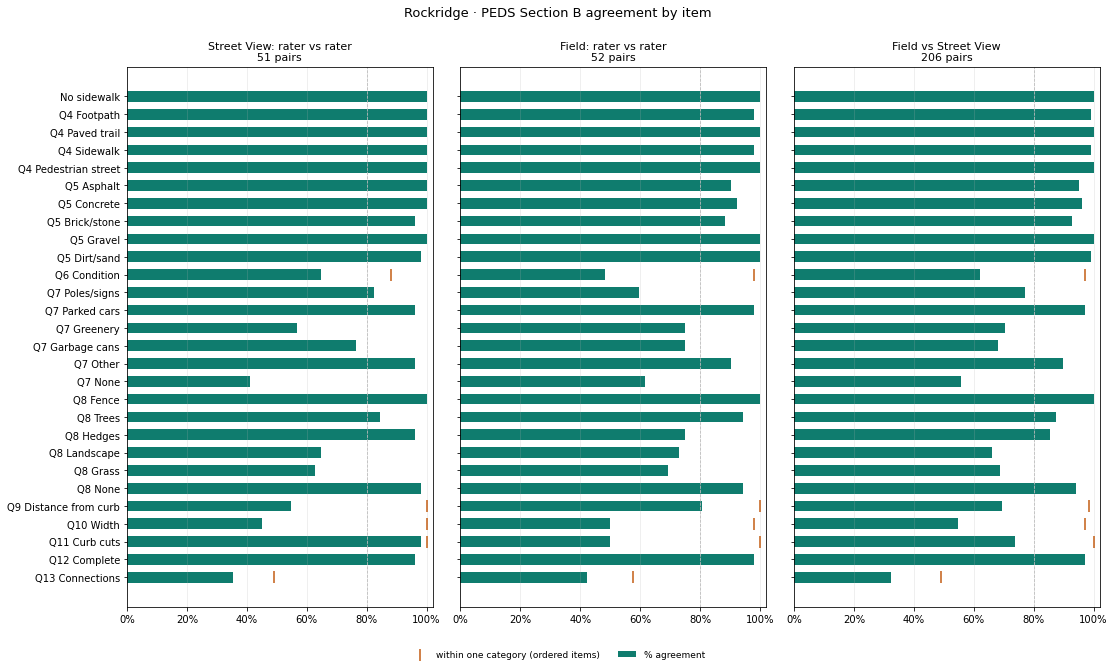

In [49]:
res = [(k, t) for k, t in RESULTS.items()]
fig, axes = plt.subplots(1, len(res), figsize=(5.2 * len(res), 9), sharey=True, squeeze=False)
order = [LABEL[i] for i in ALL][::-1]
for ax, (k, t) in zip(axes[0], res):
    t = t.set_index("item").reindex(order)
    y = np.arange(len(t))
    ax.barh(y, t["agree"], height=.6, color="#0f7c6e", label="% agreement")
    if "within1" in t:
        ax.scatter(t["within1"], y, marker="|", s=140, color="#c25a10", zorder=3, label="within one category (ordered items)")
    ax.axvline(0.8, color="#bbb", lw=.8, ls="--")
    ax.set_xlim(0, 1.02); ax.set_title(f"{k}\n{len(COMPARISONS[k])} pairs", fontsize=11)
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
    ax.set_yticks(y); ax.set_yticklabels(t.index); ax.grid(axis="x", alpha=.25)
h, l = axes[0][0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle(f"{AREA} · PEDS Section B agreement by item", fontsize=13, y=1.0)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

## 7 · Where raters differ
### Agreement by rater pair
The mean % agreement across the 28 items for each pair of raters. A low pair often points to one rater coding an item differently.

In [50]:
def by_rater_pair(p):
    rows = []
    for (ra, rb), g in p.groupby(["rater_a", "rater_b"]):
        ag = [ (g.loc[usable(g, it), f"a_{it}"] == g.loc[usable(g, it), f"b_{it}"]).mean() for it in ALL]
        rows.append(dict(rater_a=ra, rater_b=rb, pairs=len(g), mean_agreement=np.nanmean(ag)))
    return pd.DataFrame(rows).sort_values("mean_agreement")
for k, p in COMPARISONS.items():
    if len(p):
        display(Markdown(f"**{k}**"))
        display(by_rater_pair(p).style.format({"mean_agreement": "{:.1%}"}).hide(axis="index"))

**Street View: rater vs rater**

rater_a,rater_b,pairs,mean_agreement
Michael,Rico,26,80.8%
Rico,Stanley,25,86.7%


**Field: rater vs rater**

rater_a,rater_b,pairs,mean_agreement
Charlie,Stanley,26,75.7%
Clodagh,Michael,26,88.7%


**Field vs Street View**

rater_a,rater_b,pairs,mean_agreement
Charlie,Stanley,26,75.4%
Charlie,Rico,25,76.7%
Michael,Rico,26,79.9%
Clodagh,Rico,26,80.8%
Stanley,Rico,25,84.6%
Stanley,Stanley,26,87.4%
Michael,Michael,26,90.2%
Clodagh,Michael,26,90.8%


In **Field vs Street View**, a pair can be one person's own field and Street View ratings (for example Michael with Michael). Those pairs measure the method, not two different raters.

### How each rater uses the ordered items
The share of each rater's answers in each category. A rater whose answers pile up on one value (Q13 = 2 everywhere, say) usually points to a different reading of the protocol, not to what they saw.

In [51]:
for it in ORDINAL + ["q5_concrete", "q5_asphalt", "q7_none", "q8_none"]:
    sub = ratings[(ratings["no_sidewalk"] != 1) & ratings[it].notna()]
    tab = pd.crosstab([sub["method"], sub["rater_id"]], sub[it].astype(int), normalize="index")
    display(Markdown(f"**{LABEL[it]}**"))
    display(tab.style.format("{:.0%}").background_gradient(cmap="Greens", axis=1))

**Q6 Condition**

**Q9 Distance from curb**

**Q10 Width**

**Q11 Curb cuts**

**Q13 Connections**

**Q5 Concrete**

**Q5 Asphalt**

**Q7 None**

**Q8 None**

### Disagreements to review
Every item where a pair answered differently, for checking against photos or Street View.

In [52]:
def disagreements(p, name):
    rows = []
    for it in ALL:
        m = usable(p, it) & (p[f"a_{it}"] != p[f"b_{it}"])
        for _, r in p[m].iterrows():
            rows.append(dict(comparison=name, segment=r.segment, item=LABEL[it], rater_a=r.rater_a, value_a=r[f"a_{it}"],
                             rater_b=r.rater_b, value_b=r[f"b_{it}"]))
    return pd.DataFrame(rows)
DIS = pd.concat([disagreements(p, k) for k, p in COMPARISONS.items() if len(p)], ignore_index=True)
display(DIS.groupby(["comparison", "item"]).size().unstack(0).fillna(0).astype(int))
DIS.head(20)

comparison,Field vs Street View,Field: rater vs rater,Street View: rater vs rater
item,,,
Q10 Width,93,26,28
Q11 Curb cuts,54,26,1
Q12 Complete,6,1,2
Q13 Connections,139,30,33
Q4 Footpath,2,1,0
Q4 Sidewalk,2,1,0
Q5 Asphalt,10,5,0
Q5 Brick/stone,15,6,2
Q5 Concrete,8,4,0


,comparison,segment,item,rater_a,value_a,rater_b,value_b
0,Street View: rater vs rater,COL SHF–MIL W,Q5 Brick/stone,Rico,1.0,Stanley,0.0
1,Street View: rater vs rater,MIL FOR–COL S,Q5 Brick/stone,Rico,1.0,Stanley,0.0
2,Street View: rater vs rater,63RD HIL–COL S,Q5 Dirt/sand,Michael,0.0,Rico,1.0
3,Street View: rater vs rater,61ST CBY–HIL S,Q6 Condition,Rico,2.0,Stanley,3.0
4,Street View: rater vs rater,62ND CBY–HIL N,Q6 Condition,Michael,3.0,Rico,2.0
5,Street View: rater vs rater,62ND CBY–HIL S,Q6 Condition,Michael,3.0,Rico,2.0
6,Street View: rater vs rater,63RD CBY–HIL N,Q6 Condition,Michael,3.0,Rico,2.0
7,Street View: rater vs rater,63RD HIL–COL S,Q6 Condition,Michael,3.0,Rico,2.0
8,Street View: rater vs rater,ALC CBY–HIL S,Q6 Condition,Michael,3.0,Rico,2.0
9,Street View: rater vs rater,CBY 60TH–61ST E,Q6 Condition,Rico,2.0,Stanley,3.0


## 8 · Save
Writes every table to one Excel file next to this notebook.

In [53]:
with pd.ExcelWriter(EXPORT_XLSX) as xl:
    overview.rename_axis("comparison").to_excel(xl, sheet_name="Overview")
    for k, t in RESULTS.items():
        t[[c for c in MAIN_COLS if c in t]].to_excel(xl, sheet_name=k.replace(":", "")[:31], index=False)
    pd.concat([t[[c for c in APPENDIX_COLS if c in t]].assign(comparison=k) for k, t in RESULTS.items()]).to_excel(
        xl, sheet_name="Appendix chance-corrected", index=False)
    gq.to_excel(xl, sheet_name="Whole question")
    pd.concat([by_rater_pair(p).assign(comparison=k) for k, p in COMPARISONS.items() if len(p)])[
        ["comparison", "rater_a", "rater_b", "pairs", "mean_agreement"]].to_excel(xl, sheet_name="Rater pairs", index=False)
    DIS.to_excel(xl, sheet_name="Disagreements", index=False)
    cov.to_excel(xl, sheet_name="Coverage")
    problems.to_excel(xl, sheet_name="Data checks", index=False)
    log.to_excel(xl, sheet_name="Exclusions and merges", index=False)
    ratings.to_excel(xl, sheet_name="Clean ratings", index=False)
print("saved", EXPORT_XLSX)

/var/folders/95/x26hj81d0gg4m9v5bc23dpp80000gn/T/ipykernel_80963/1198118741.py:1: UserWarning: Pandas requires version '3.0.5' or newer of 'xlsxwriter' (version '3.0.1' currently installed).
  with pd.ExcelWriter(EXPORT_XLSX) as xl:


saved Rockridge_rater_agreement.xlsx


## 9 · Map: sidewalk condition (Q6)
Each block face is drawn on its side of the street and colored by Q6 condition. Darker blue means better condition, orange means under repair, and gray means no sidewalk. Use the layer switch at the top right to choose **Field**, **Street View**, or **Field vs Street View**.

A **dashed line with a white ring** means the ratings disagree. In the field and Street View layers, the raters gave different answers. In the comparison layer, the field and Street View answers differ. A disagreement is drawn at the poorer answer. Hover over a block for a summary, or click it for every rater's answer.

Segment lines come from OpenStreetMap street centerlines, matched on the street and cross-street names in `streetview.html`. The first run fetches them from the Overpass API and caches them as `osm_streets_<area>.json` next to this notebook (see `peds_map.py`). Running the cell saves the map as a standalone HTML file and opens it in your default browser.

In [54]:
import importlib, peds_map
importlib.reload(peds_map)   # pick up edits to peds_map.py without restarting

LINES, _ = peds_map.segment_lines(AREA, final_code)
rated = set(ratings.segment)
no_line = sorted(rated - set(LINES))
if no_line: print("No map geometry for:", no_line)
MAP, MAP_TABLE = peds_map.build_map(ratings, {k: v for k, v in LINES.items() if k in rated}, AREA)
MAP_HTML = f"{AREA}_sidewalk_condition_map.html"
MAP.save(MAP_HTML)

# open in the default browser (VS Code's notebook viewer blocks the map's scripts)
import webbrowser, pathlib
MAP_URL = pathlib.Path(MAP_HTML).resolve().as_uri()
webbrowser.open(MAP_URL)
print("saved and opened", MAP_URL)

saved and opened file:///Users/clodagh/Desktop/Fall%202026/290/audit/Rockridge_sidewalk_condition_map.html


### Table view
The same data as the map: Q6 for each segment and method, and the segments where raters disagree.

In [55]:
wide = MAP_TABLE.pivot(index="segment", columns="method", values="shown").rename(columns={"field": "field Q6", "gsv": "Street View Q6"})
wide["field raters disagree"] = MAP_TABLE[MAP_TABLE.method == "field"].set_index("segment").disagree
wide["Street View raters disagree"] = MAP_TABLE[MAP_TABLE.method == "gsv"].set_index("segment").disagree
wide["field ≠ Street View"] = wide["field Q6"] != wide["Street View Q6"]
display(wide[["field raters disagree", "Street View raters disagree", "field ≠ Street View"]].sum().rename("segments").to_frame())
dis_q6 = MAP_TABLE[MAP_TABLE.disagree].pivot(index="segment", columns="method", values="detail").fillna("")
display(dis_q6)

,segments
method,
field raters disagree,27
Street View raters disagree,18
field ≠ Street View,18


method,field,gsv
segment,,
60TH CBY–CLA S,Stanley (v1): Under repair; Charlie (v1): Good,
61ST CBY–HIL N,Stanley (v1): Good; Charlie (v1): Fair,
61ST CBY–HIL S,Stanley (v1): Good; Charlie (v1): Fair,Rico: Fair; Stanley: Good
62ND CBY–HIL N,Clodagh (v1): Fair; Michael (v1): Good,Rico: Fair; Michael: Good
62ND CBY–HIL S,,Rico: Fair; Michael: Good
62ND HIL–COL N,Michael (v1): Good; Clodagh (v1): Fair,
62ND HIL–COL S,Michael (v1): Good; Clodagh (v1): Fair,
63RD CBY–HIL N,,Rico: Fair; Michael: Good
63RD HIL–COL S,,Rico: Fair; Michael: Good
